In [1]:

from google.colab import files
uploaded = files.upload()


Saving Global_Warming_Cleaned.zip to Global_Warming_Cleaned.zip


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Global_Warming_Cleaned.zip")

# Set visualization defaults
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Number of columns:", len(df.columns))
print("Missing cells:", df.isnull().sum().sum())

display(df.head())


Dataset loaded successfully!
Shape: (100000, 26)
Number of columns: 26
Missing cells: 0


,Country,Year,Temperature_Anomaly,CO2_Emissions,Population,Forest_Area,GDP,Renewable_Energy_Usage,Methane_Emissions,Sea_Level_Rise,...,Waste_Management,Per_Capita_Emissions,Industrial_Activity,Air_Pollution_Index,Biodiversity_Index,Ocean_Acidification,Fossil_Fuel_Usage,Energy_Consumption_Per_Capita,Policy_Score,Average_Temperature
0,Country_103,1913,-1.163537,8.876061e+08,1.627978e+08,54.872178,6.139887e+12,76.710013,8.317626e+06,8.111839,...,82.691409,2.285351,4.060975,150.285539,90.073356,8.025470,39.163860,1480.164332,78.870012,20.825292
1,Country_180,1950,-0.432122,4.497517e+08,4.281359e+08,84.051006,2.601447e+12,68.450021,6.206540e+06,42.025915,...,59.322883,17.411668,85.300604,27.305922,88.289837,8.021719,28.252554,1482.730048,32.600905,28.720587
2,Country_93,2014,0.444954,4.579080e+08,4.926732e+08,72.295357,5.192677e+12,36.725699,1.056885e+06,20.953840,...,94.982931,12.039703,83.804880,216.911429,86.936256,7.647408,61.548382,706.918809,37.671300,15.014084
3,Country_15,2020,-1.171616,5.049503e+08,1.252169e+09,17.259684,8.252128e+12,77.547901,1.986813e+06,45.599595,...,62.064250,2.853957,47.014265,35.869182,44.904331,7.569353,82.423750,2616.238324,86.581725,-1.277086
4,Country_107,1964,-0.564038,6.898891e+08,2.932960e+08,44.438605,8.560746e+12,10.019576,3.313252e+06,7.652150,...,84.431279,19.801173,89.379613,284.263093,8.102916,8.015415,29.964450,4975.683780,20.618406,2.861989


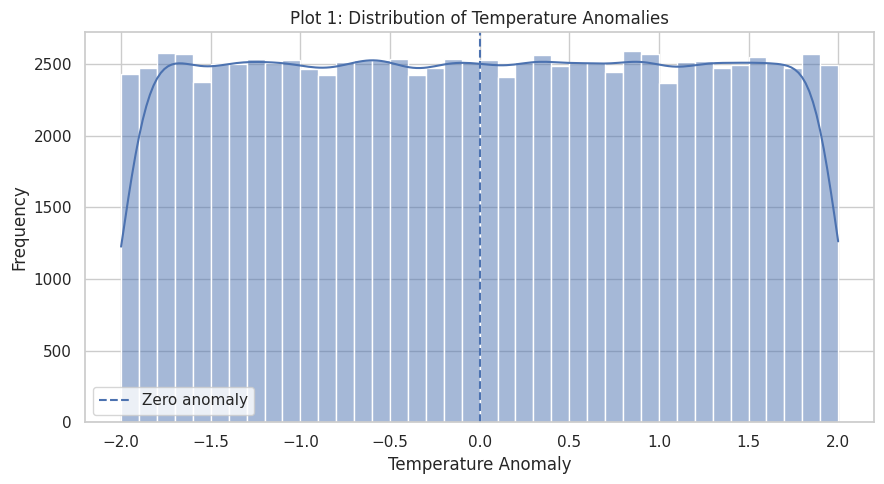

In [5]:

# Plot 1 of 30: Histogram
plt.figure(figsize=(9, 5))
sns.histplot(df["Temperature_Anomaly"], bins=40, kde=True)
plt.axvline(0, linestyle="--", label="Zero anomaly")
plt.title("Plot 1: Distribution of Temperature Anomalies")
plt.xlabel("Temperature Anomaly")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


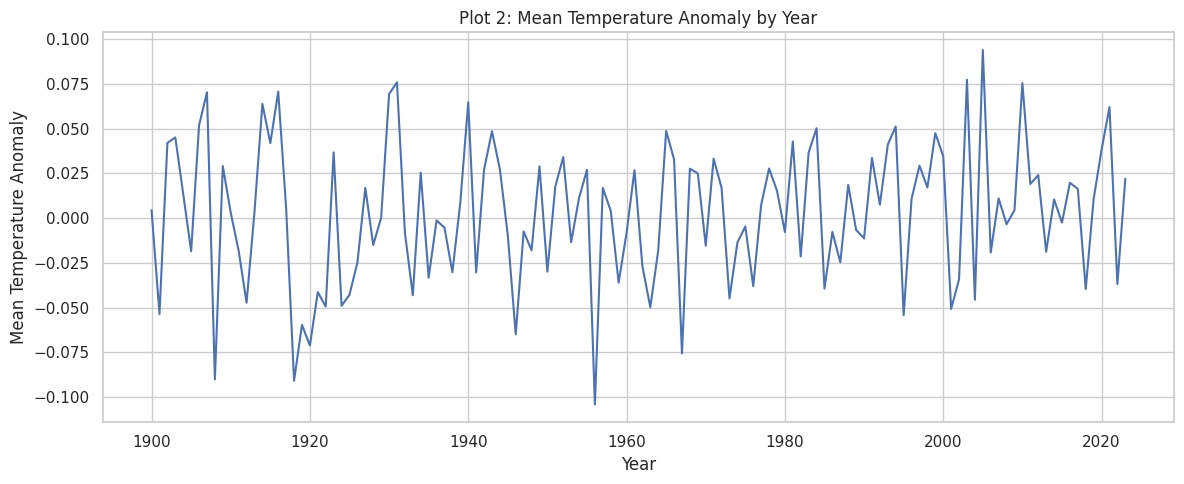

In [6]:

# Plot 2 of 30: Line chart
yearly_anomaly = df.groupby("Year")["Temperature_Anomaly"].mean()
plt.figure(figsize=(12, 5))
plt.plot(yearly_anomaly.index, yearly_anomaly.values)
plt.title("Plot 2: Mean Temperature Anomaly by Year")
plt.xlabel("Year")
plt.ylabel("Mean Temperature Anomaly")
plt.tight_layout()
plt.show()


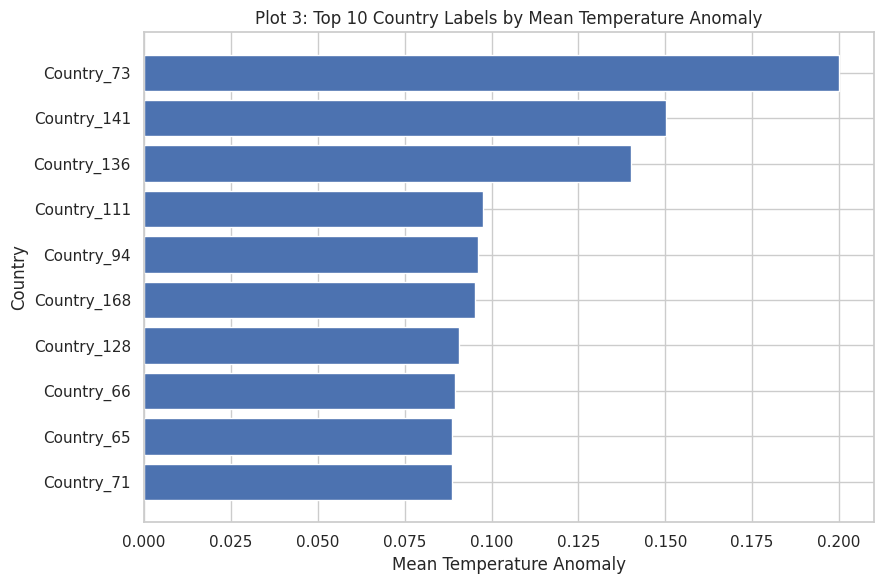

In [7]:

# Plot 3 of 30: Horizontal bar chart
top_anomaly = (
    df.groupby("Country")["Temperature_Anomaly"]
        .mean().nlargest(10).sort_values()
        )
plt.figure(figsize=(9, 6))
plt.barh(top_anomaly.index, top_anomaly.values)
plt.title("Plot 3: Top 10 Country Labels by Mean Temperature Anomaly")
plt.xlabel("Mean Temperature Anomaly")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


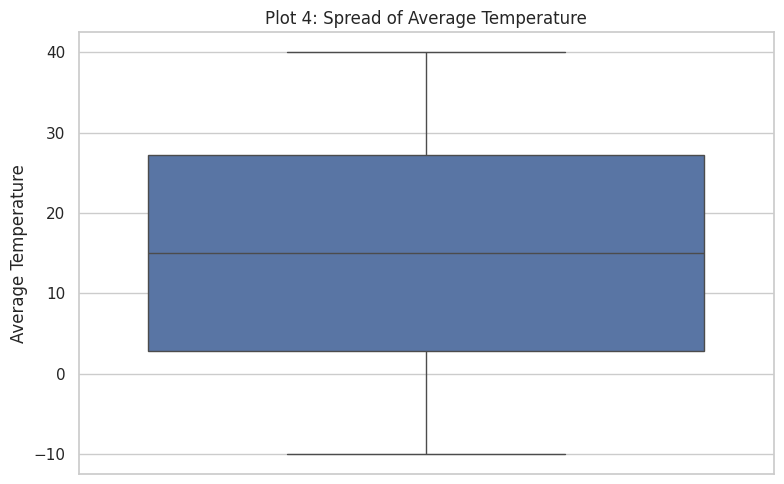

In [8]:

# Plot 4 of 30: Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(y=df["Average_Temperature"])
plt.title("Plot 4: Spread of Average Temperature")
plt.ylabel("Average Temperature")
plt.tight_layout()
plt.show()


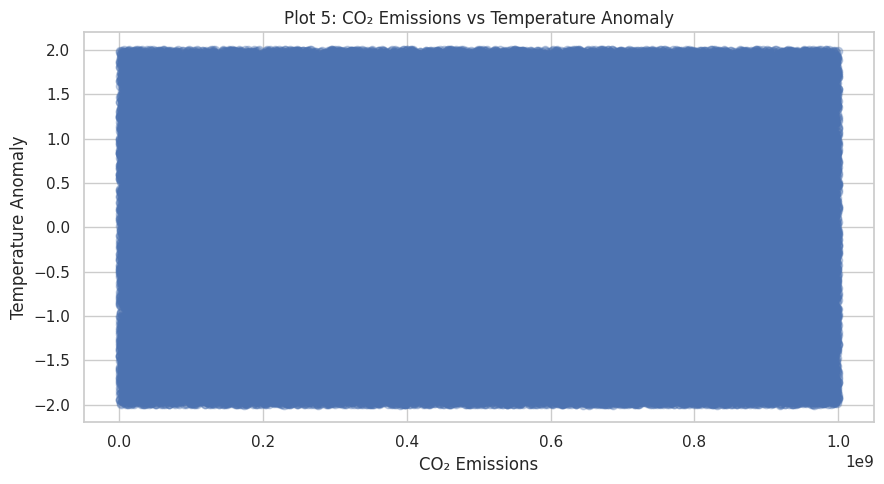

In [9]:

# Plot 5 of 30: Scatter plot
plt.figure(figsize=(9, 5))
plt.scatter(df["CO2_Emissions"], df["Temperature_Anomaly"], alpha=0.3)
plt.title("Plot 5: CO₂ Emissions vs Temperature Anomaly")
plt.xlabel("CO₂ Emissions")
plt.ylabel("Temperature Anomaly")
plt.tight_layout()
plt.show()


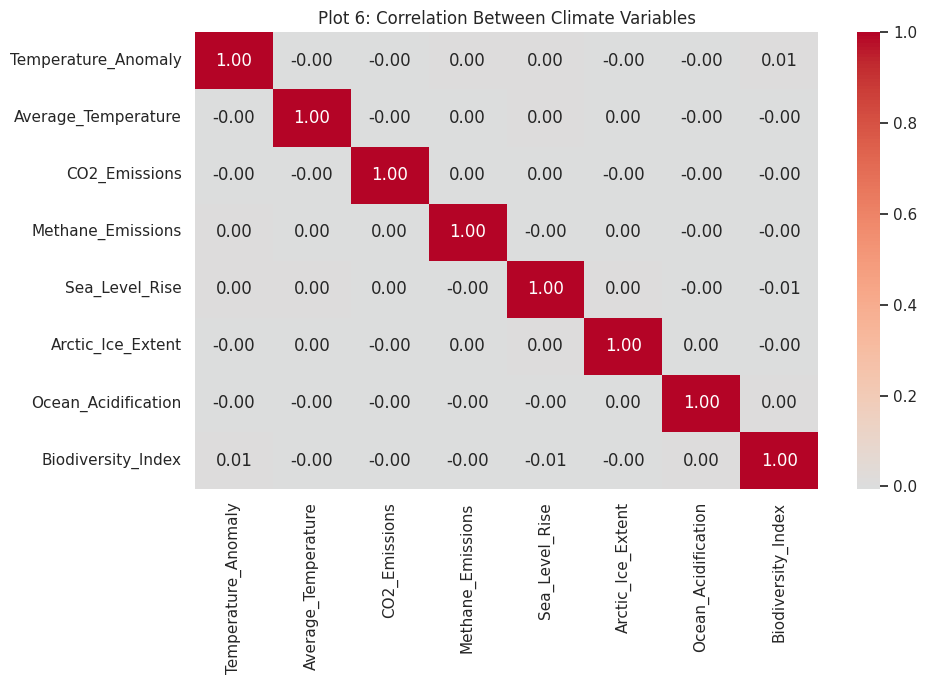

In [10]:

# Plot 6 of 30: Correlation heatmap
corr_cols = [
    "Temperature_Anomaly", "Average_Temperature", "CO2_Emissions",
        "Methane_Emissions", "Sea_Level_Rise", "Arctic_Ice_Extent",
            "Ocean_Acidification", "Biodiversity_Index"
            ]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Plot 6: Correlation Between Climate Variables")
plt.tight_layout()
plt.show()


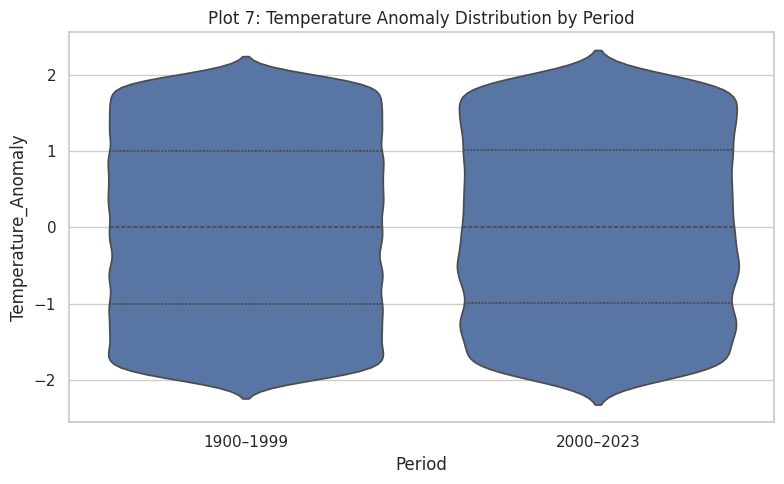

In [11]:

# Plot 7 of 30: Violin plot
period = pd.cut(
    df["Year"],
        bins=[1899, 1999, 2023],
            labels=["1900–1999", "2000–2023"]
            )
plot_df = pd.DataFrame({
                "Period": period,
                    "Temperature_Anomaly": df["Temperature_Anomaly"]
                    })
plt.figure(figsize=(8, 5))
sns.violinplot(data=plot_df, x="Period", y="Temperature_Anomaly", inner="quartile")
plt.title("Plot 7: Temperature Anomaly Distribution by Period")
plt.tight_layout()
plt.show()


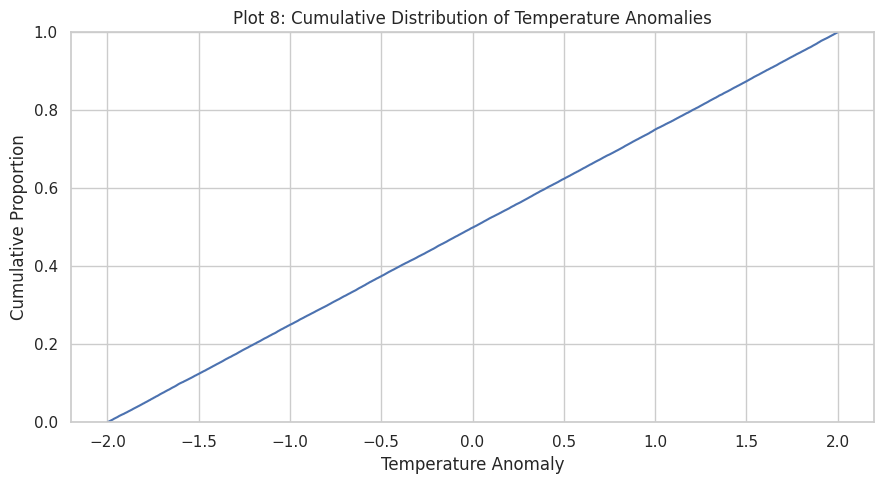

In [12]:

# Plot 8 of 30: ECDF
plt.figure(figsize=(9, 5))
sns.ecdfplot(data=df, x="Temperature_Anomaly")
plt.title("Plot 8: Cumulative Distribution of Temperature Anomalies")
plt.xlabel("Temperature Anomaly")
plt.ylabel("Cumulative Proportion")
plt.tight_layout()
plt.show()


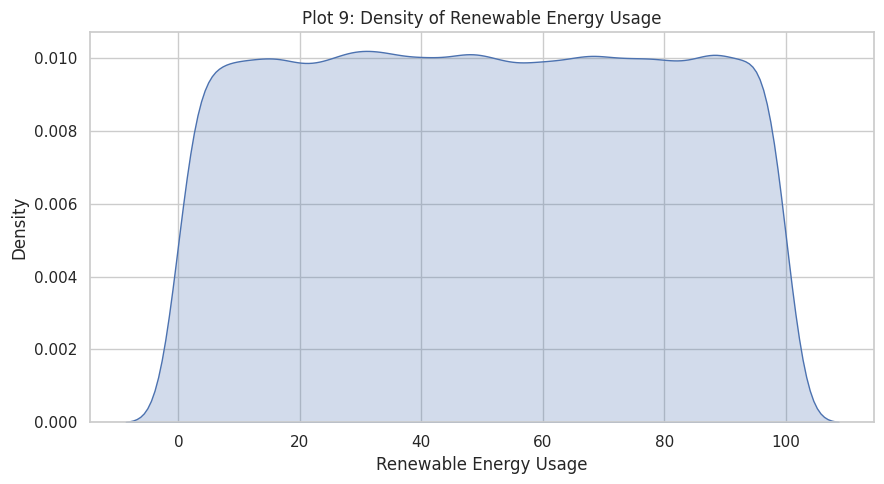

In [13]:

# Plot 9 of 30: KDE
plt.figure(figsize=(9, 5))
sns.kdeplot(data=df, x="Renewable_Energy_Usage", fill=True)
plt.title("Plot 9: Density of Renewable Energy Usage")
plt.xlabel("Renewable Energy Usage")
plt.tight_layout()
plt.show()


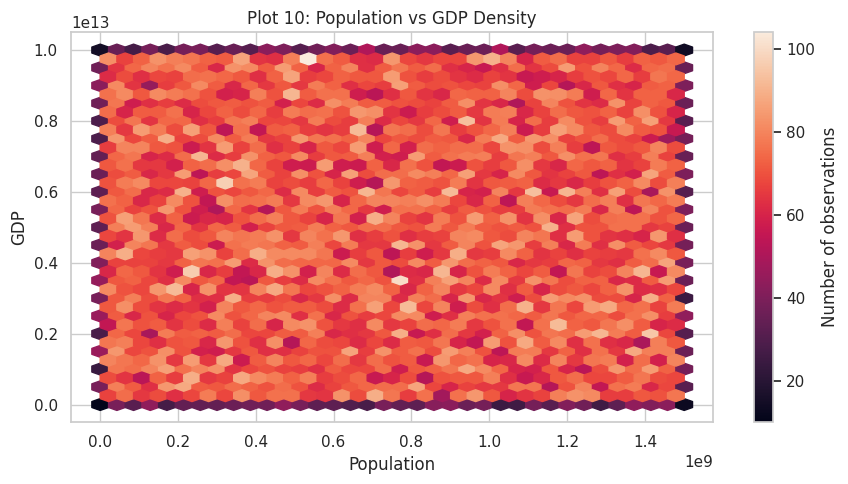

In [14]:

# Plot 10 of 30: Hexbin
plt.figure(figsize=(9, 5))
plt.hexbin(df["Population"], df["GDP"], gridsize=35, mincnt=1)
plt.colorbar(label="Number of observations")
plt.title("Plot 10: Population vs GDP Density")
plt.xlabel("Population")
plt.ylabel("GDP")
plt.tight_layout()
plt.show()


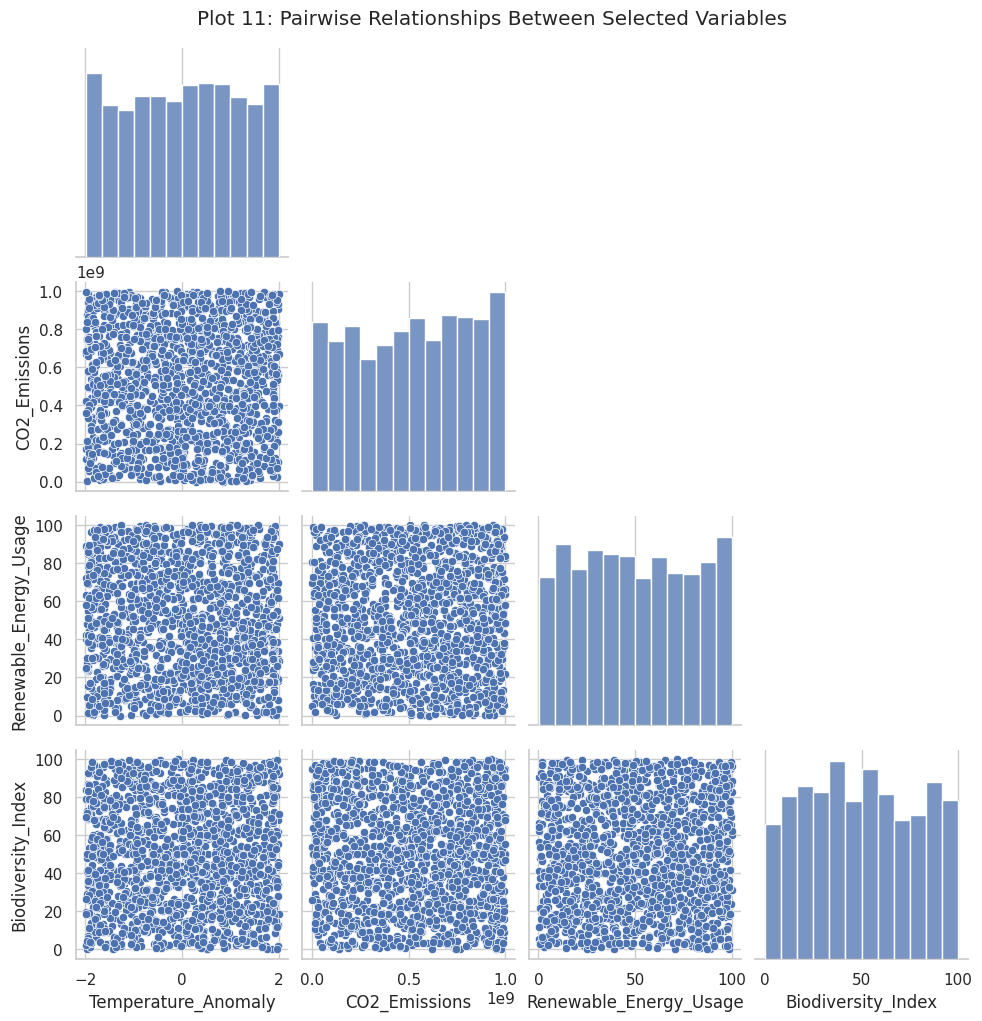

In [15]:

# Plot 11 of 30: Pair plot
pair_cols = [
    "Temperature_Anomaly", "CO2_Emissions",
        "Renewable_Energy_Usage", "Biodiversity_Index"
        ]
pair_sample = df[pair_cols].sample(n=min(1500, len(df)), random_state=42)
sns.pairplot(pair_sample, corner=True, diag_kind="hist")
plt.suptitle("Plot 11: Pairwise Relationships Between Selected Variables", y=1.02)
plt.show()


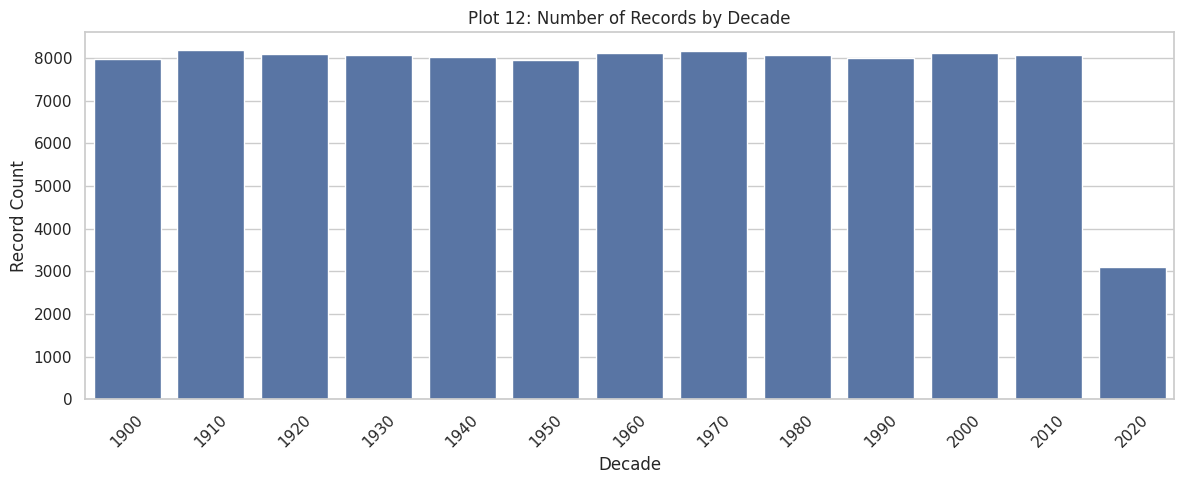

In [16]:

# Plot 12 of 30: Count plot
decade = (df["Year"] // 10) * 10
decade_df = pd.DataFrame({"Decade": decade})
plt.figure(figsize=(12, 5))
sns.countplot(data=decade_df, x="Decade", order=sorted(decade_df["Decade"].unique()))
plt.title("Plot 12: Number of Records by Decade")
plt.xlabel("Decade")
plt.ylabel("Record Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


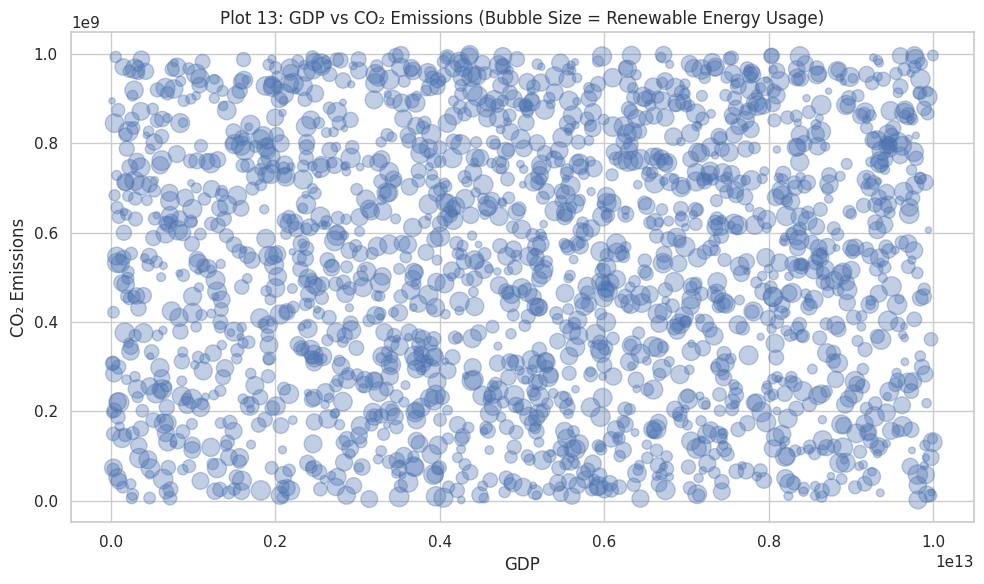

In [17]:

# Plot 13 of 30: Bubble chart
bubble = df.sample(n=min(2000, len(df)), random_state=42)
sizes = 20 + 180 * (
    bubble["Renewable_Energy_Usage"] /
        bubble["Renewable_Energy_Usage"].max()
        )
plt.figure(figsize=(10, 6))
plt.scatter(
            bubble["GDP"], bubble["CO2_Emissions"],
                s=sizes, alpha=0.35
                )
plt.title("Plot 13: GDP vs CO₂ Emissions (Bubble Size = Renewable Energy Usage)")
plt.xlabel("GDP")
plt.ylabel("CO₂ Emissions")
plt.tight_layout()
plt.show()


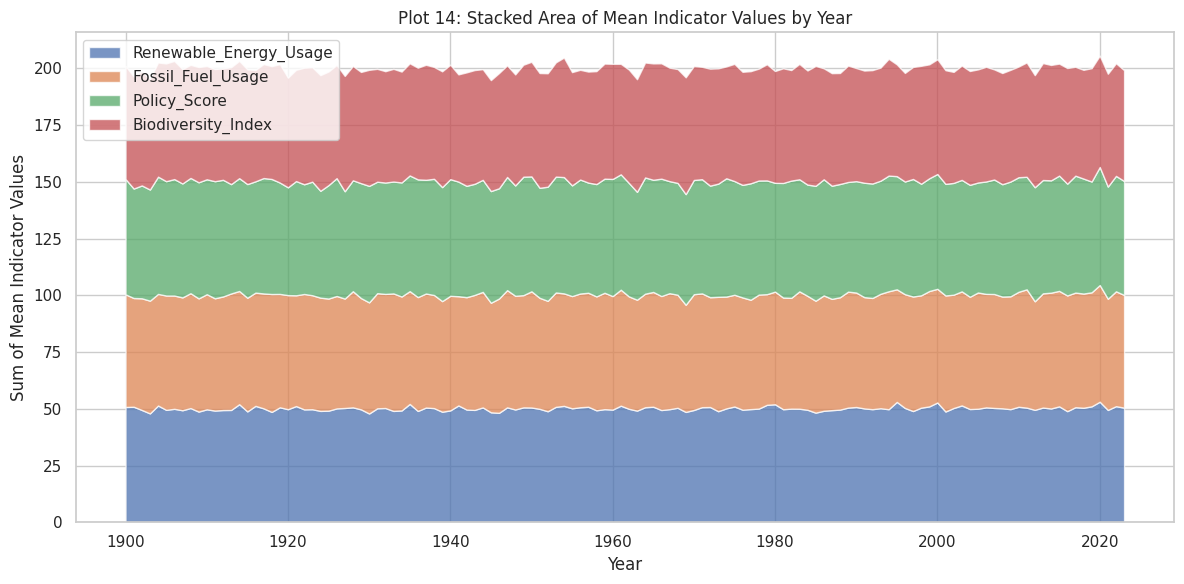

In [18]:

# Plot 14 of 30: Area chart
area_cols = [
    "Renewable_Energy_Usage", "Fossil_Fuel_Usage",
        "Policy_Score", "Biodiversity_Index"
        ]
area_means = df.groupby("Year")[area_cols].mean()
plt.figure(figsize=(12, 6))
plt.stackplot(
            area_means.index,
                [area_means[c] for c in area_cols],
                    labels=area_cols,
                        alpha=0.75
                        )
plt.title("Plot 14: Stacked Area of Mean Indicator Values by Year")
plt.xlabel("Year")
plt.ylabel("Sum of Mean Indicator Values")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


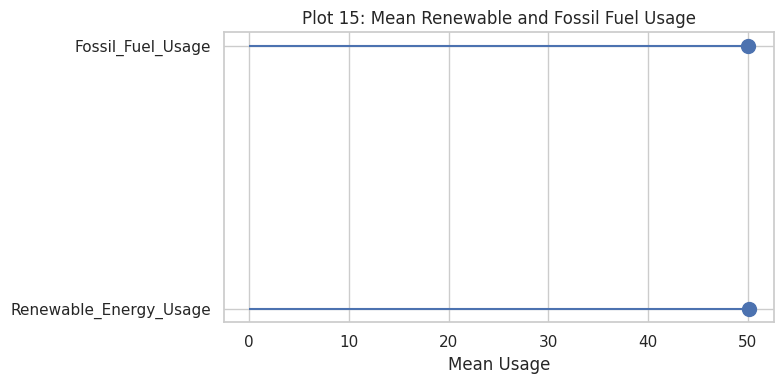

In [19]:

# Plot 15 of 30: Lollipop chart
means = df[["Renewable_Energy_Usage", "Fossil_Fuel_Usage"]].mean()

plt.figure(figsize=(8, 4))
plt.hlines(y=means.index, xmin=0, xmax=means.values)
plt.plot(means.values, means.index, "o", markersize=10)
plt.title("Plot 15: Mean Renewable and Fossil Fuel Usage")
plt.xlabel("Mean Usage")
plt.tight_layout()
plt.show()


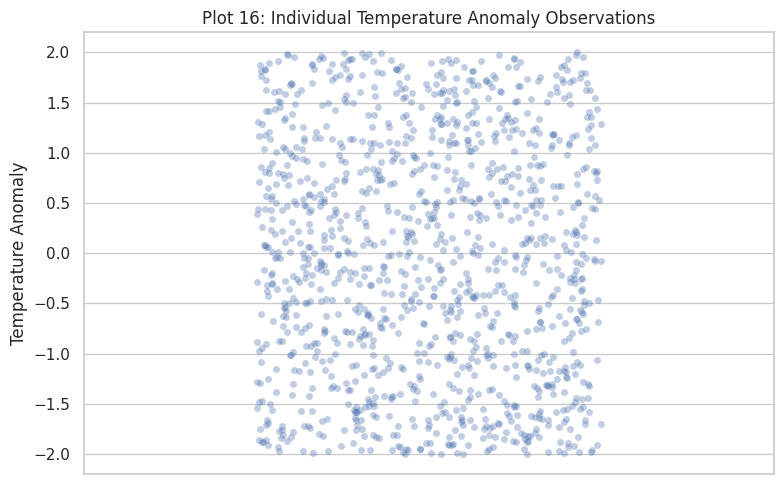

In [20]:

# Plot 16 of 30: Strip plot
strip_sample = df.sample(n=min(1200, len(df)), random_state=7)

plt.figure(figsize=(8, 5))
sns.stripplot(
    data=strip_sample,
        y="Temperature_Anomaly",
            jitter=0.25,
                alpha=0.35
                )
plt.title("Plot 16: Individual Temperature Anomaly Observations")
plt.ylabel("Temperature Anomaly")
plt.tight_layout()
plt.show()


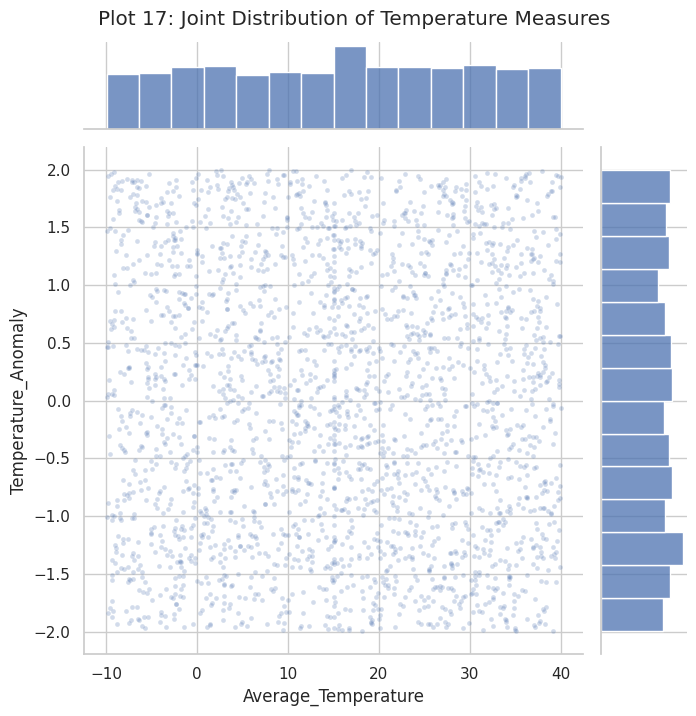

In [21]:

# Plot 17 of 30: Joint plot
joint_sample = df.sample(n=min(2500, len(df)), random_state=21)

g = sns.jointplot(
    data=joint_sample,
        x="Average_Temperature",
            y="Temperature_Anomaly",
                kind="scatter",
                    height=7,
                        joint_kws={"alpha": 0.25, "s": 12}
                        )

g.fig.suptitle(
                            "Plot 17: Joint Distribution of Temperature Measures",
                                y=1.02
                                )
plt.show()


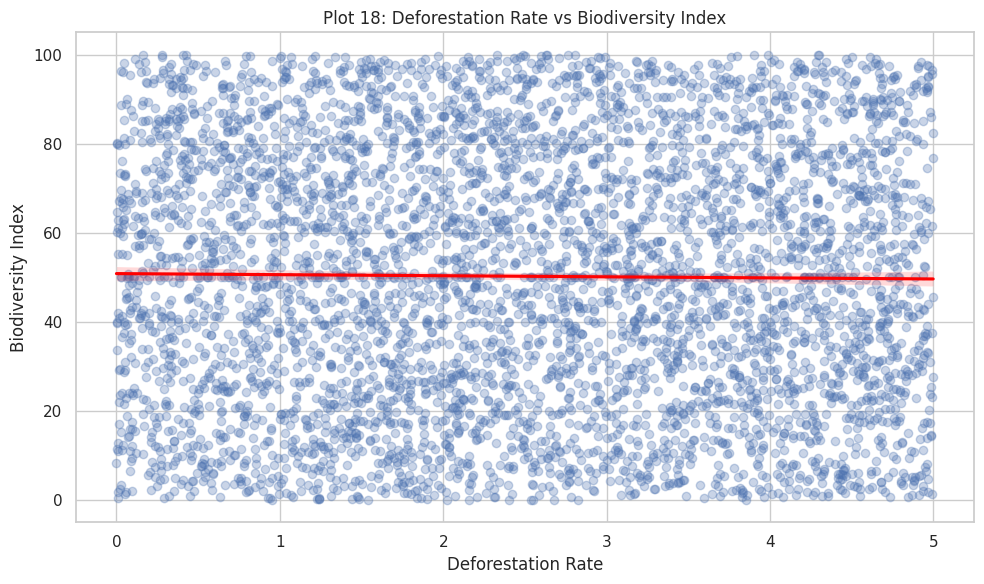

In [22]:
# PLOT 18: Deforestation Rate vs Biodiversity Index

plt.figure(figsize=(10, 6))
sns.regplot(
    data=df.sample(min(5000, len(df)), random_state=42),
        x="Deforestation_Rate",
            y="Biodiversity_Index",
                scatter_kws={"alpha": 0.3},
                    line_kws={"color": "red"}
                    )
plt.title("Plot 18: Deforestation Rate vs Biodiversity Index")
plt.xlabel("Deforestation Rate")
plt.ylabel("Biodiversity Index")
plt.tight_layout()
plt.show()

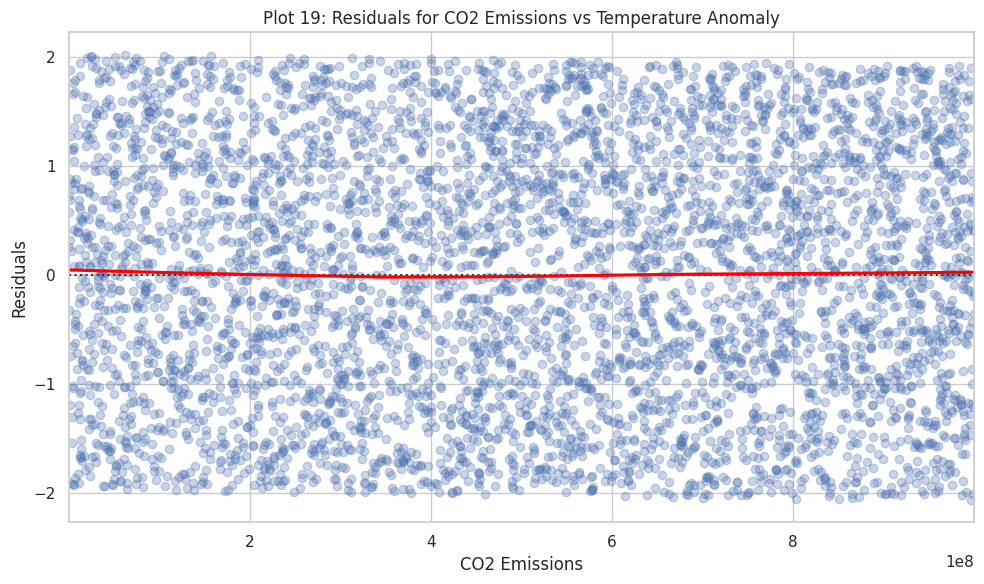

In [23]:
# PLOT 19: Residual Analysis

sample = df[["CO2_Emissions", "Temperature_Anomaly"]].dropna()
sample = sample.sample(min(5000, len(sample)), random_state=42)

sns.residplot(
    data=sample,
        x="CO2_Emissions",
            y="Temperature_Anomaly",
                lowess=True,
                    scatter_kws={"alpha": 0.3},
                        line_kws={"color": "red"}
                        )
plt.title("Plot 19: Residuals for CO2 Emissions vs Temperature Anomaly")
plt.xlabel("CO2 Emissions")
plt.ylabel("Residuals")
plt.tight_layout()
plt.show()

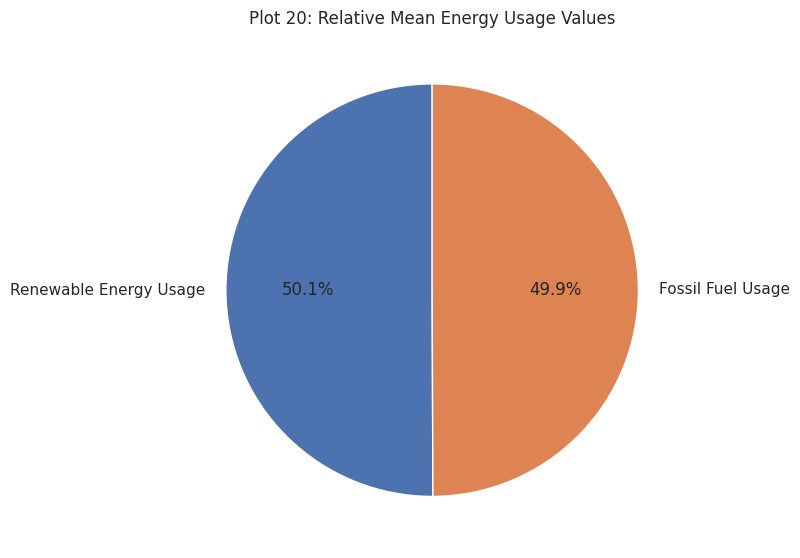

In [24]:
# PLOT 20: Relative Mean Renewable and Fossil Fuel Usage

means = df[
    ["Renewable_Energy_Usage", "Fossil_Fuel_Usage"]
    ].mean()

plt.figure(figsize=(8, 8))
plt.pie(
        means.values,
            labels=["Renewable Energy Usage", "Fossil Fuel Usage"],
                autopct="%1.1f%%",
                    startangle=90
                    )
plt.title("Plot 20: Relative Mean Energy Usage Values")
plt.tight_layout()
plt.show()

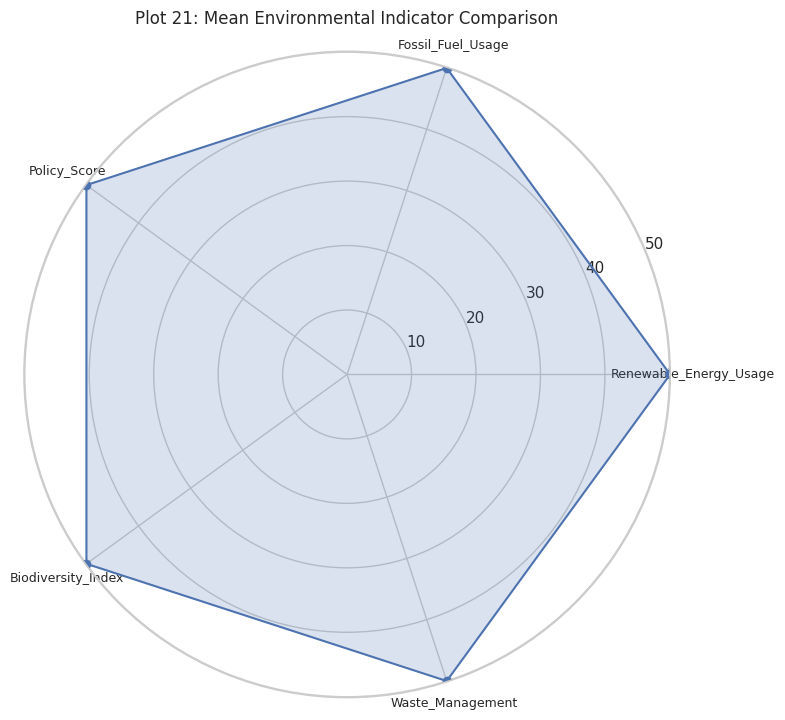

In [25]:
# PLOT 21: Environmental Indicator Radar Chart

import numpy as np

columns = [
    "Renewable_Energy_Usage",
        "Fossil_Fuel_Usage",
            "Policy_Score",
                "Biodiversity_Index",
                    "Waste_Management"
                    ]

values = df[columns].mean().values
angles = np.linspace(0, 2 * np.pi, len(columns), endpoint=False)
values = np.append(values, values[0])
angles = np.append(angles, angles[0])

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
ax.plot(angles, values, marker="o")
ax.fill(angles, values, alpha=0.2)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(columns, fontsize=9)
ax.set_title("Plot 21: Mean Environmental Indicator Comparison", pad=20)
plt.tight_layout()
plt.show()

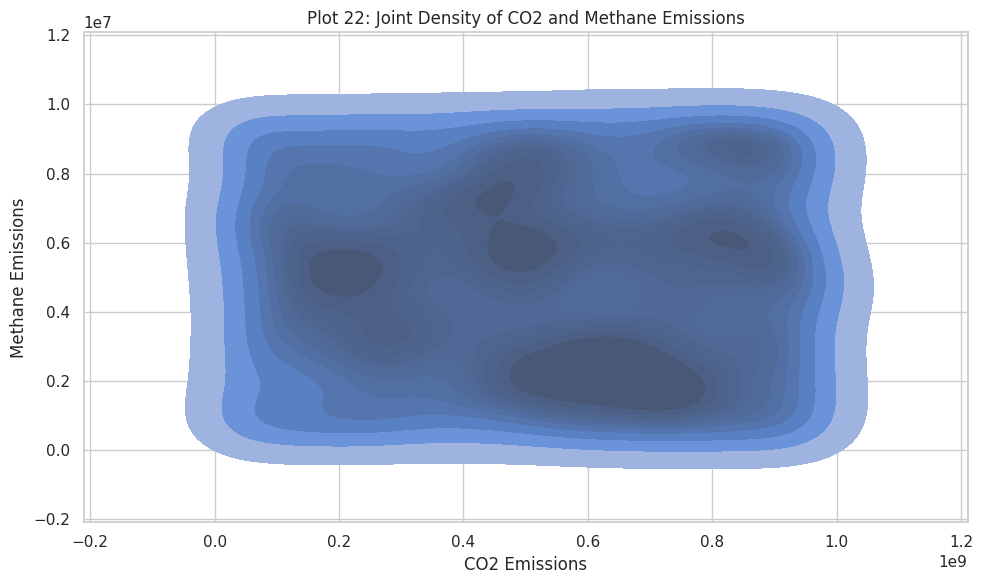

In [26]:
# PLOT 22: CO2 and Methane Emissions Density

sample = df[["CO2_Emissions", "Methane_Emissions"]].dropna()
sample = sample.sample(min(5000, len(sample)), random_state=42)

plt.figure(figsize=(10, 6))
sns.kdeplot(
    data=sample,
        x="CO2_Emissions",
            y="Methane_Emissions",
                fill=True,
                    levels=12,
                        thresh=0.05
                        )
plt.title("Plot 22: Joint Density of CO2 and Methane Emissions")
plt.xlabel("CO2 Emissions")
plt.ylabel("Methane Emissions")
plt.tight_layout()
plt.show()

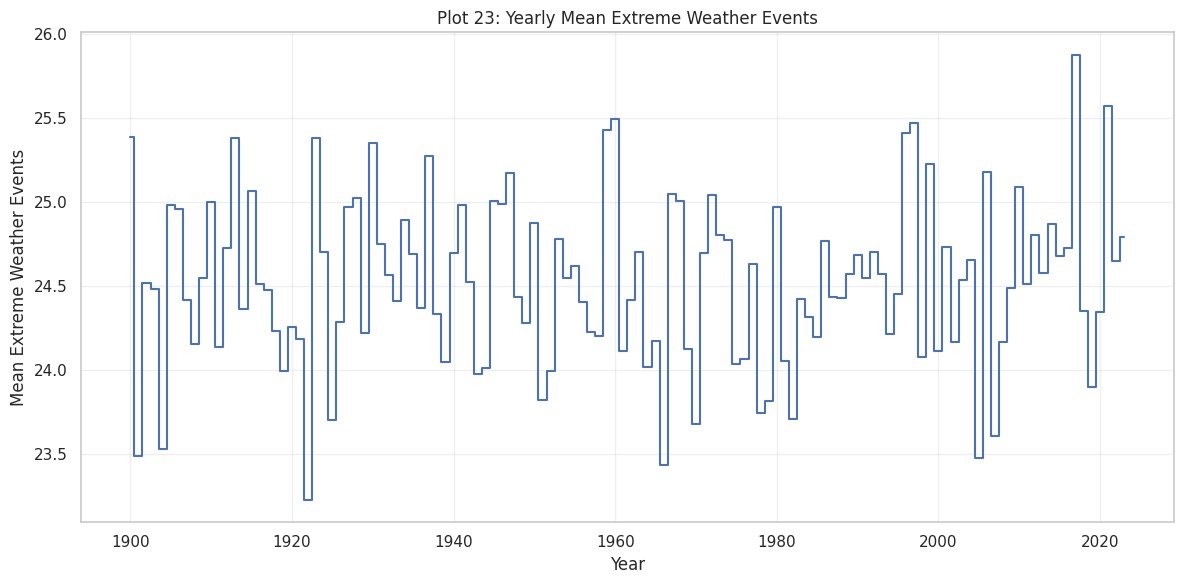

In [27]:
# PLOT 23: Yearly Extreme Weather Events

yearly_events = df.groupby("Year")["Extreme_Weather_Events"].mean()

plt.figure(figsize=(12, 6))
plt.step(
    yearly_events.index,
        yearly_events.values,
            where="mid"
            )
plt.title("Plot 23: Yearly Mean Extreme Weather Events")
plt.xlabel("Year")
plt.ylabel("Mean Extreme Weather Events")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

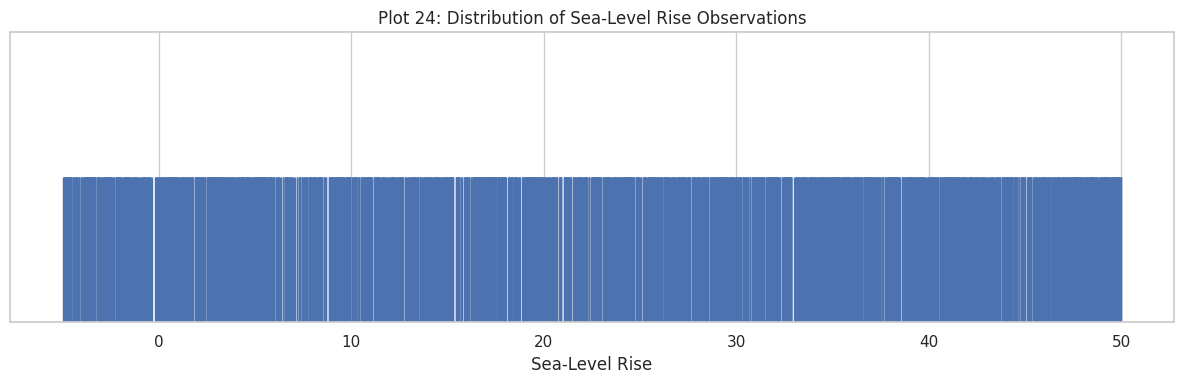

In [28]:
# PLOT 24: Sea-Level Rise Rug Plot

sample = df["Sea_Level_Rise"].dropna()
sample = sample.sample(min(3000, len(sample)), random_state=42)

plt.figure(figsize=(12, 4))
sns.rugplot(x=sample, height=0.5)
plt.title("Plot 24: Distribution of Sea-Level Rise Observations")
plt.xlabel("Sea-Level Rise")
plt.yticks([])
plt.tight_layout()
plt.show()

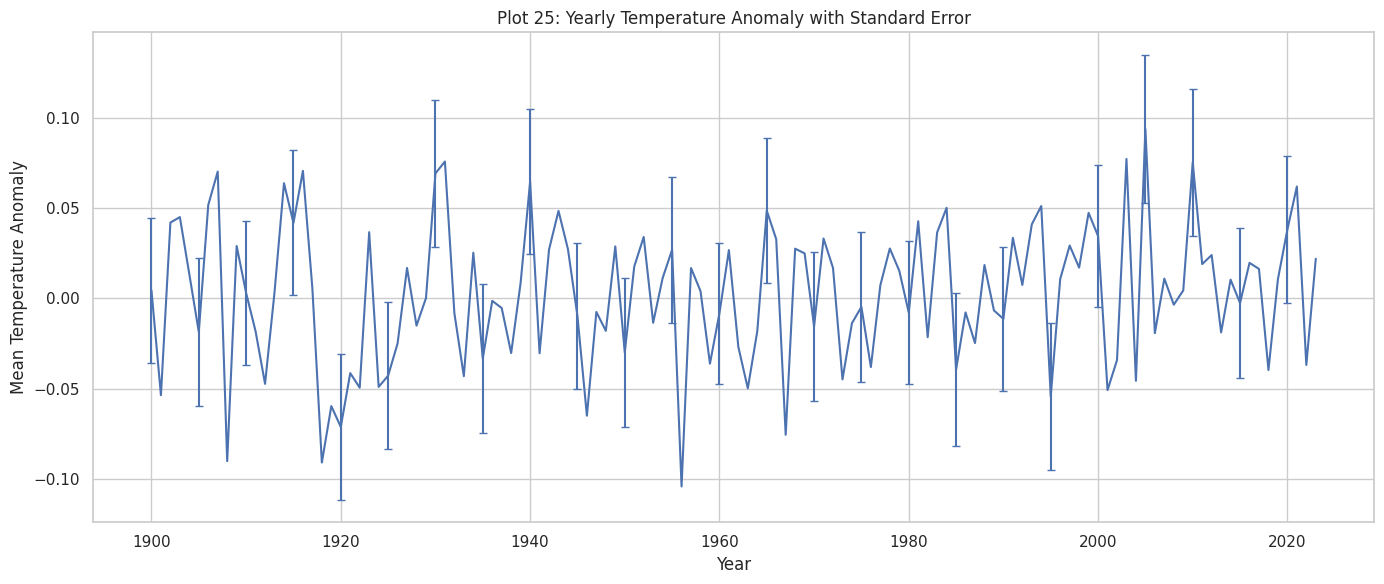

In [29]:
# PLOT 25: Yearly Mean Temperature Anomaly with Standard Error

yearly = df.groupby("Year")["Temperature_Anomaly"].agg(
    ["mean", "std", "count"]
    )
yearly["se"] = yearly["std"] / np.sqrt(yearly["count"])

plt.figure(figsize=(14, 6))
plt.errorbar(
        yearly.index,
            yearly["mean"],
                yerr=yearly["se"],
                    fmt="-",
                        errorevery=5,
                            capsize=3
                            )
plt.title("Plot 25: Yearly Temperature Anomaly with Standard Error")
plt.xlabel("Year")
plt.ylabel("Mean Temperature Anomaly")
plt.tight_layout()
plt.show()

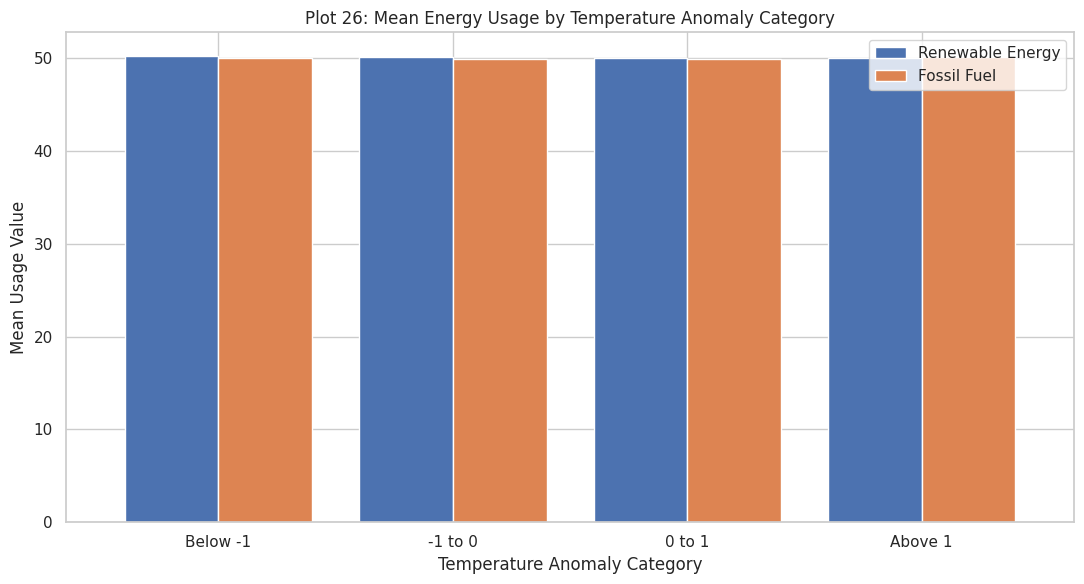

In [30]:
# PLOT 26: Grouped Energy Usage by Temperature Anomaly Category

plot_df = df.copy()

plot_df["Anomaly_Category"] = pd.cut(
    plot_df["Temperature_Anomaly"],
        bins=[-np.inf, -1, 0, 1, np.inf],
            labels=["Below -1", "-1 to 0", "0 to 1", "Above 1"]
            )

grouped = plot_df.groupby(
                "Anomaly_Category", observed=False
                )[["Renewable_Energy_Usage", "Fossil_Fuel_Usage"]].mean()

grouped.plot(kind="bar", figsize=(11, 6), width=0.8)
plt.title("Plot 26: Mean Energy Usage by Temperature Anomaly Category")
plt.xlabel("Temperature Anomaly Category")
plt.ylabel("Mean Usage Value")
plt.xticks(rotation=0)
plt.legend(["Renewable Energy", "Fossil Fuel"])
plt.tight_layout()
plt.show()

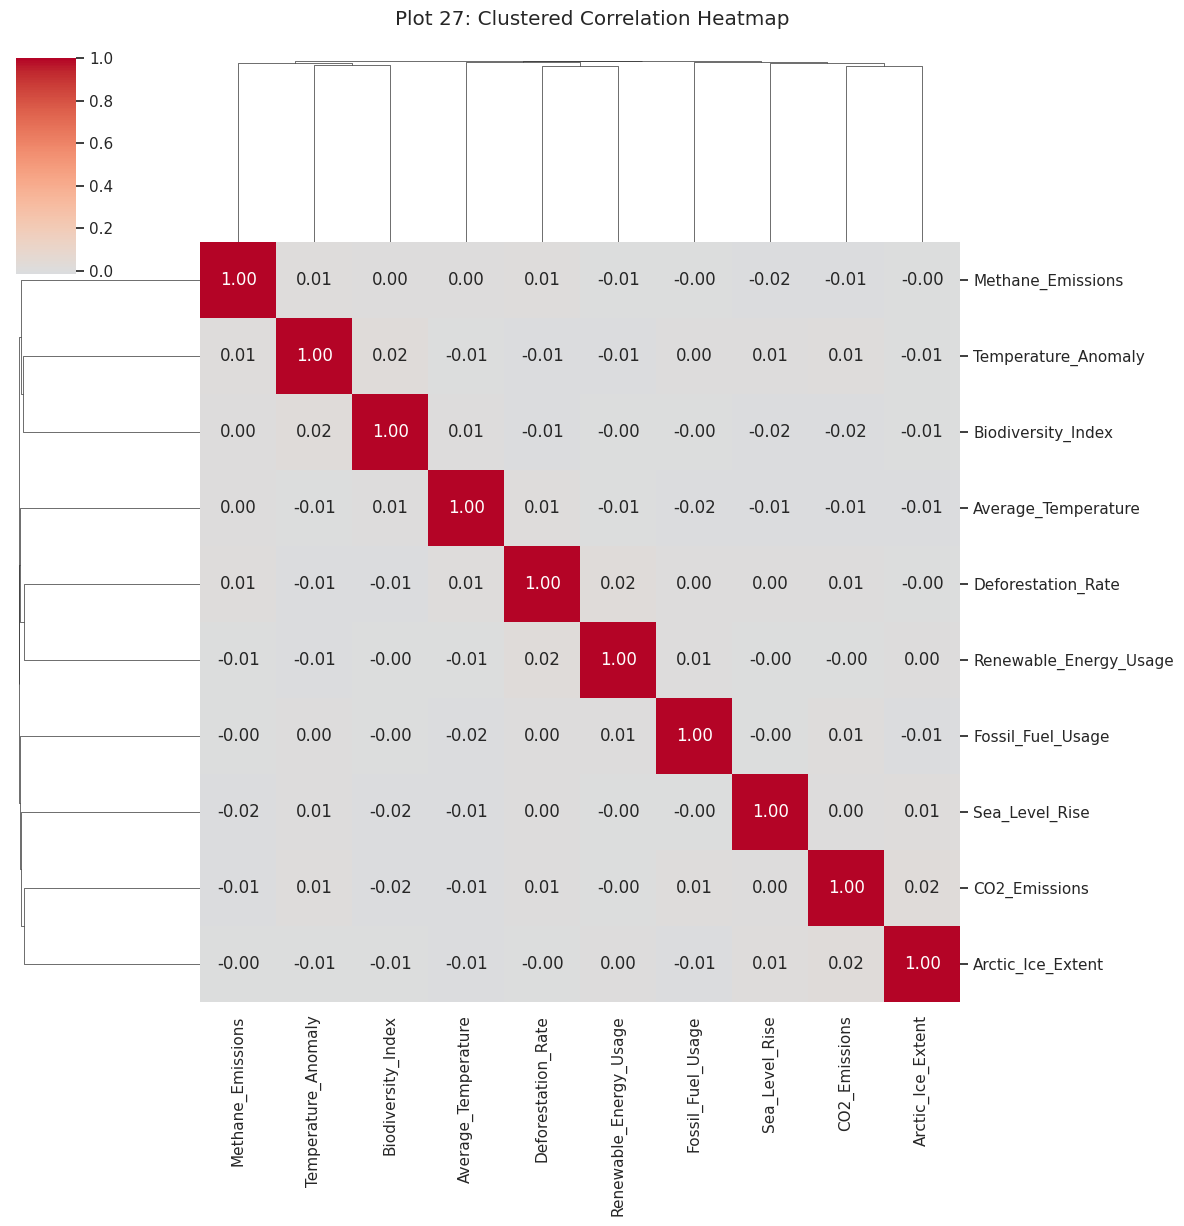

In [31]:
# PLOT 27: Clustered Correlation Heatmap

columns = [
    "Temperature_Anomaly",
        "Average_Temperature",
            "CO2_Emissions",
                "Methane_Emissions",
                    "Sea_Level_Rise",
                        "Arctic_Ice_Extent",
                            "Biodiversity_Index",
                                "Deforestation_Rate",
                                    "Renewable_Energy_Usage",
                                        "Fossil_Fuel_Usage"
                                        ]

sample = df[columns].sample(min(10000, len(df)), random_state=42)

sns.clustermap(
                                            sample.corr(),
                                                annot=True,
                                                    fmt=".2f",
                                                        cmap="coolwarm",
                                                            center=0,
                                                                figsize=(12, 12)
                                                                )
plt.suptitle("Plot 27: Clustered Correlation Heatmap", y=1.02)
plt.show()

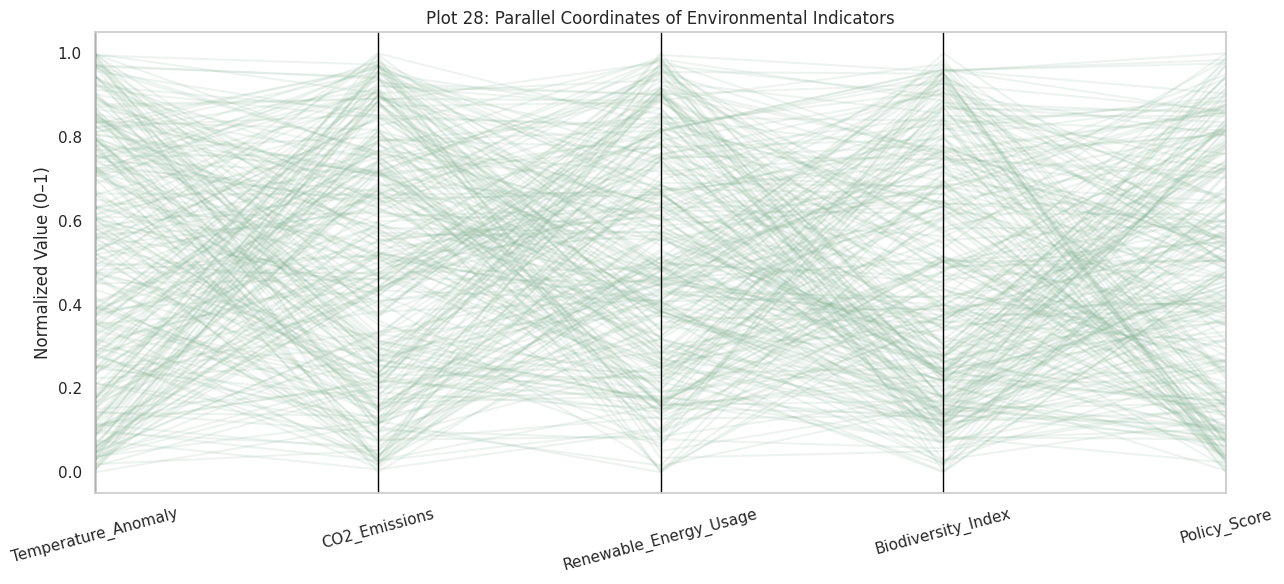

In [32]:
# PLOT 28: Parallel Coordinates

from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import MinMaxScaler

columns = [
    "Temperature_Anomaly",
        "CO2_Emissions",
            "Renewable_Energy_Usage",
                "Biodiversity_Index",
                    "Policy_Score"
                    ]

sample = df[columns].sample(min(300, len(df)), random_state=42).copy()

scaler = MinMaxScaler()
sample[columns] = scaler.fit_transform(sample[columns])

sample["Group"] = "Observation"

plt.figure(figsize=(13, 6))
parallel_coordinates(
                        sample,
                            class_column="Group",
                                cols=columns,
                                    alpha=0.15
                                    )
plt.title("Plot 28: Parallel Coordinates of Environmental Indicators")
plt.ylabel("Normalized Value (0–1)")
plt.xticks(rotation=15)
plt.legend().remove()
plt.tight_layout()
plt.show()

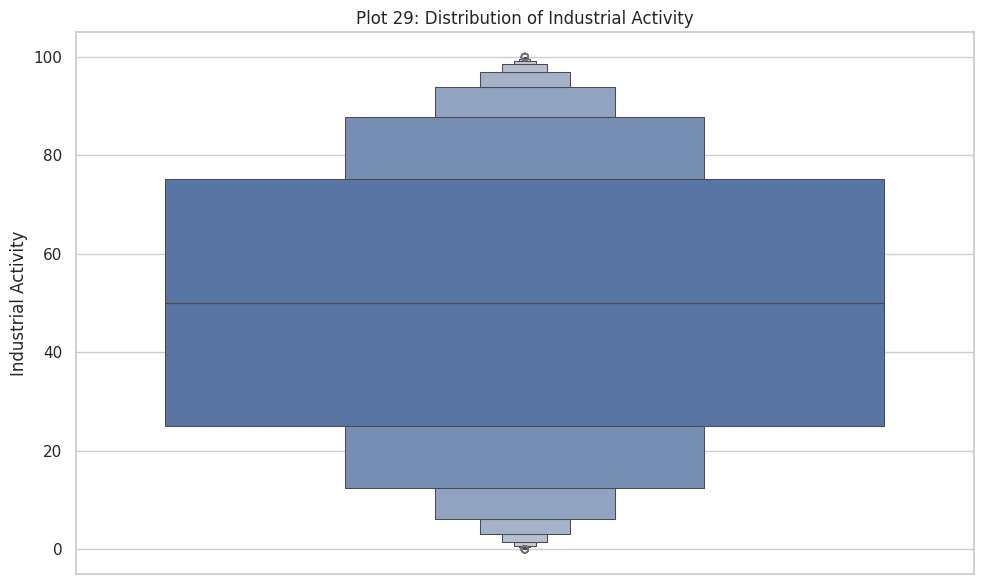

In [33]:
# PLOT 29: Industrial Activity Distribution

plt.figure(figsize=(10, 6))
sns.boxenplot(y=df["Industrial_Activity"].dropna())
plt.title("Plot 29: Distribution of Industrial Activity")
plt.ylabel("Industrial Activity")
plt.tight_layout()
plt.show()

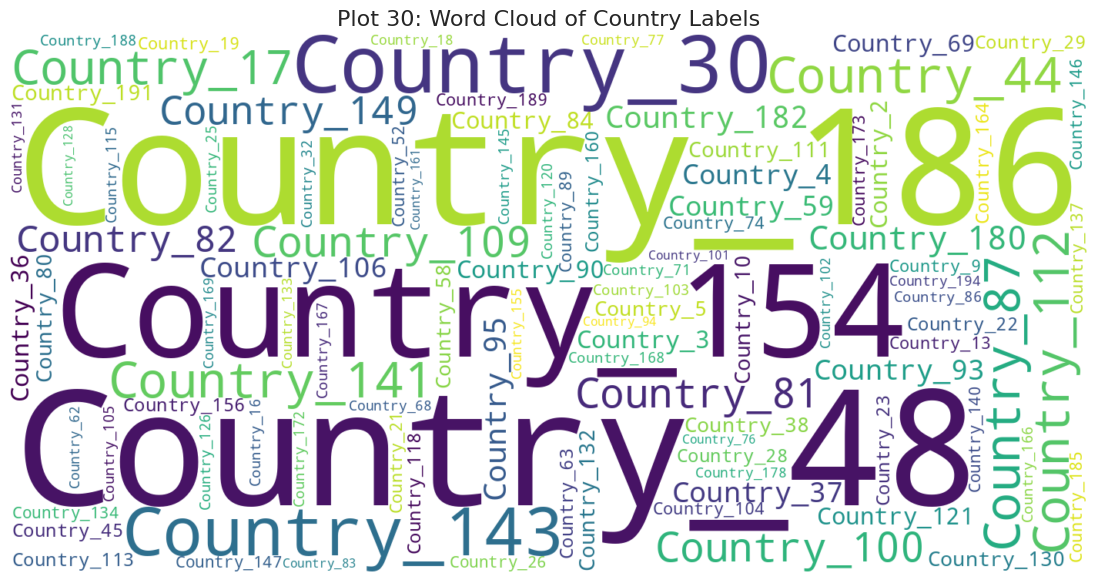

In [34]:
# PLOT 30: Word Cloud of Country Labels

from wordcloud import WordCloud

country_frequencies = df["Country"].astype(str).value_counts().to_dict()

wordcloud = WordCloud(
    width=1400,
        height=700,
            background_color="white",
                colormap="viridis",
                    max_words=100
                    ).generate_from_frequencies(country_frequencies)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Plot 30: Word Cloud of Country Labels", fontsize=16)
plt.show()